# PatchVision: Data Understanding and Preprocessing (CUB-200-2011)

In [9]:
import os, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2
ROOT = Path("data")                    # where the dataset will live
CUB = ROOT / "CUB_200_2011"

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

## 1. Download and extract
Official page: https://www.vision.caltech.edu/datasets/cub_200_2011/ (the archive is hosted on Caltech's data repository, about 1.1 GB).

In [13]:
ROOT.mkdir(exist_ok=True)
if not CUB.exists():
    !wget -c "https://data.caltech.edu/records/65de6-vp158/files/CUB_200_2011.tgz?download=1" -O data/CUB_200_2011.tgz
    !tar -xzf data/CUB_200_2011.tgz -C data
print(sorted(p.name for p in CUB.iterdir()))

['README', 'attributes', 'bounding_boxes.txt', 'classes.txt', 'image_class_labels.txt', 'images', 'images.txt', 'parts', 'train_test_split.txt']


## 2. Load the metadata
Key files inside `CUB_200_2011/`:
- `images.txt`: image_id, relative path
- `image_class_labels.txt`: image_id, class_id (1-200)
- `train_test_split.txt`: image_id, is_train (1 = official train)
- `classes.txt`: class_id, class name
- `bounding_boxes.txt`: image_id, x, y, width, height (kept for optional analysis only)

In [14]:
images  = pd.read_csv(CUB/"images.txt", sep=" ", names=["image_id", "path"])
labels  = pd.read_csv(CUB/"image_class_labels.txt", sep=" ", names=["image_id", "class_id"])
split   = pd.read_csv(CUB/"train_test_split.txt", sep=" ", names=["image_id", "is_train"])
classes = pd.read_csv(CUB/"classes.txt", sep=" ", names=["class_id", "class_name"])
bbox    = pd.read_csv(CUB/"bounding_boxes.txt", sep=" ", names=["image_id", "x", "y", "w", "h"])

df = (images.merge(labels, on="image_id")
            .merge(split, on="image_id")
            .merge(classes, on="class_id")
            .merge(bbox, on="image_id"))
df["label"] = df["class_id"] - 1                       # 0-indexed for PyTorch
df["class_name"] = df["class_name"].str.split(".", n=1).str[1].str.replace("_", " ")
df["filepath"] = df["path"].apply(lambda p: str(CUB/"images"/p))

assert len(df) == 11788 and df["label"].nunique() == 200
assert df["filepath"].apply(os.path.exists).all(), "missing image files"
print(df.shape)
df.head()

(11788, 11)


,image_id,path,class_id,is_train,class_name,x,y,w,h,label,filepath
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,Black footed Albatross,60.0,27.0,325.0,304.0,0,data/CUB_200_2011/images/001.Black_footed_Alba...
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,Black footed Albatross,139.0,30.0,153.0,264.0,0,data/CUB_200_2011/images/001.Black_footed_Alba...
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,Black footed Albatross,14.0,112.0,388.0,186.0,0,data/CUB_200_2011/images/001.Black_footed_Alba...
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,Black footed Albatross,112.0,90.0,255.0,242.0,0,data/CUB_200_2011/images/001.Black_footed_Alba...
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,Black footed Albatross,70.0,50.0,134.0,303.0,0,data/CUB_200_2011/images/001.Black_footed_Alba...


In [17]:
len(df['class_name'].unique())

200

- There are 200 species of bird mostly North American
- Each photo has one label: the species.
- **Size and balance**: each species has about 60 images. It’s well balanced

In [18]:
df['label'].unique()

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

- These are the species IDs. Each number from 0 to 199 stands for one of the 200 bird species, so seeing exactly 0 through 199 confirms all 200 classes are present.

In [20]:
id_to_name = df.drop_duplicates("label").set_index("label")["class_name"].sort_index()
print(id_to_name.head())   # 0 -> Black footed Albatross, etc.

label
0    Black footed Albatross
1          Laysan Albatross
2           Sooty Albatross
3         Groove billed Ani
4            Crested Auklet
Name: class_name, dtype: object


In [21]:
print(id_to_name[57])      # name for label 57

Pigeon Guillemot


## 3. Exploratory data analysis

Official train: 5994 | official test: 5794
Missing values: 0
Images per class (all): min=41, max=60, mean=58.9
Images per class (train): min=29, max=30


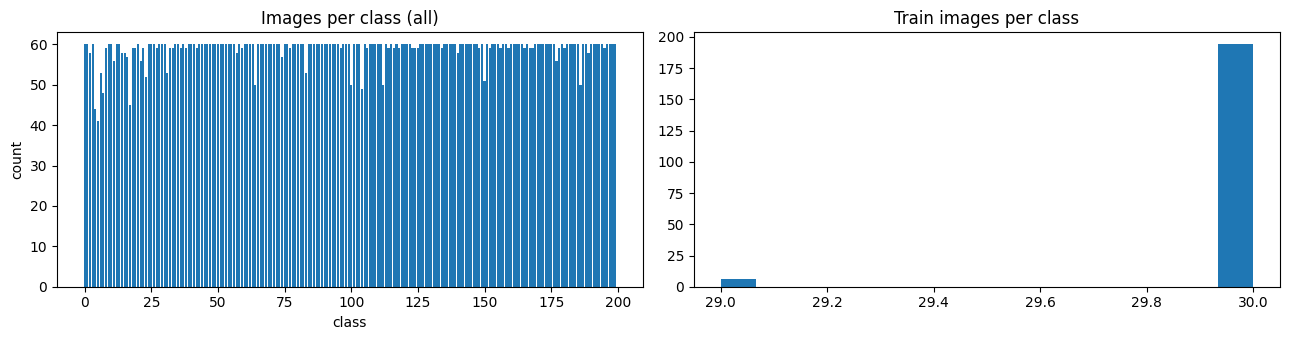

In [22]:
print("Official train:", (df.is_train == 1).sum(), "| official test:", (df.is_train == 0).sum())
print("Missing values:", int(df.isna().sum().sum()))

counts = df.groupby("label").size()
print(f"Images per class (all): min={counts.min()}, max={counts.max()}, mean={counts.mean():.1f}")
tr_counts = df[df.is_train == 1].groupby("label").size()
print(f"Images per class (train): min={tr_counts.min()}, max={tr_counts.max()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].bar(counts.index, counts.values); ax[0].set_title("Images per class (all)")
ax[0].set_xlabel("class"); ax[0].set_ylabel("count")
ax[1].hist(tr_counts.values, bins=15); ax[1].set_title("Train images per class")
plt.tight_layout(); plt.show()

## Dataset Overview and Class Balance

**Dataset verification**
- Merged the CUB-200-2011 metadata files (images, labels, official split, class names, bounding boxes) into one DataFrame.
- Official split: **5,994 training** and **5,794 test** images, **11,788** in total. This matches the published dataset statistics.
- **0 missing values** in the metadata.
- All **200 class labels (0 to 199)** are present.

**Images per class (full dataset)**
- Range: **41 to 60** images per class, mean **58.9**.
- Most classes have exactly 60 images.
- A small number of classes, mostly among the lower-indexed labels, have fewer.

**Images per class (training split)**
- Nearly uniform: **194 classes have 30 images** and **6 classes have 29**.
- The histogram groups classes by their training image count, so it shows a tall bar at 30 and a very small bar at 29.

**Implications**
- The imbalance is minimal, so no class weighting or resampling is applied.
- **Macro-averaged F1** is reported alongside accuracy so every class counts equally.
- The validation split is **stratified**, so every species appears in it.
- With about 30 training images per class (about 27 after holding out 10% for validation), the dataset is small for traininnd data augmentation.

          width    height    aspect
count  11788.00  11788.00  11788.00
mean     467.89    386.03      1.26
std       63.93     70.89      0.29
min      121.00    120.00      0.38
25%      495.00    333.00      1.08
50%      500.00    375.00      1.33
75%      500.00    434.00      1.50
max      500.00    500.00      3.60

Color modes:
 mode
RGB    11780
L          8
Name: count, dtype: int64


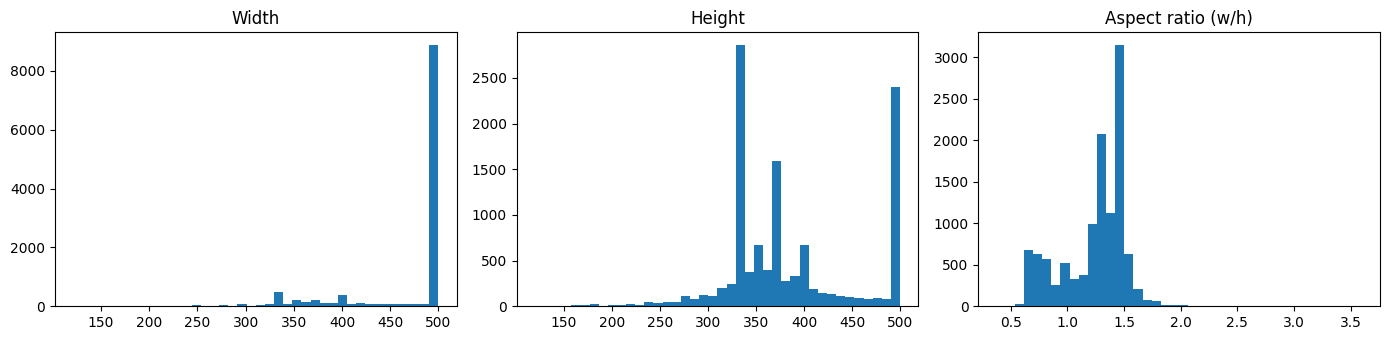


Bird bbox as fraction of image area:
 count    11788.000
mean         0.346
std          0.176
min          0.050
25%          0.207
50%          0.317
75%          0.454
max          1.000
Name: bbox_area_frac, dtype: float64


In [23]:
# Image size, aspect ratio, and color mode (reads headers only, so it is fast)
def meta(fp):
    with Image.open(fp) as im:
        return im.size[0], im.size[1], im.mode
m = df["filepath"].apply(meta)
df["width"]  = [a for a, _, _ in m]
df["height"] = [b for _, b, _ in m]
df["mode"]   = [c for _, _, c in m]
df["aspect"] = df["width"] / df["height"]

print(df[["width", "height", "aspect"]].describe().round(2))
print("\nColor modes:\n", df["mode"].value_counts())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(df.width, bins=40);  ax[0].set_title("Width")
ax[1].hist(df.height, bins=40); ax[1].set_title("Height")
ax[2].hist(df.aspect, bins=40); ax[2].set_title("Aspect ratio (w/h)")
plt.tight_layout(); plt.show()

# How much of the frame does the bird occupy? (context for the augmentation choice)
df["bbox_area_frac"] = (df.w * df.h) / (df.width * df.height)
print("\nBird bbox as fraction of image area:\n", df["bbox_area_frac"].describe().round(3))

## Image Properties and Bird Size Analysis

**Image dimensions**
- Maximum width is **500 px**, and most images (the large spike in the width histogram) are exactly 500 px wide.
- Height varies more: median **375 px**, with common values around 333, 375 and 500 px.
- The smallest image is about **121 × 120 px**. A few images are small, but nearly all are large enough that resizing to 224 × 224 loses little detail.
- Because sizes differ across images, all inputs must be resized to a fixed **224 × 224** before batching.

**Aspect ratio (width / height)**
- Median **1.33** (standard 4:3 landscape), mean 1.26.
- Most images fall between about 0.6 and 2.0. Some are portrait (below 1), and a few extreme cases reach 3.6.
- A direct resize to 224 × 224 slightly distorts the aspect ratio for most images and distorts the extreme ones more. This is noted as a limitation. The alternative, Resize(256) followed by CenterCrop(224), preserves proportions but can crop part of the bird.

**Color modes**
- **11,780 images are RGB** and **8 are grayscale (single channel)**.
- Grayscale images are converted to RGB (`.convert("RGB")`) so every input has 3 channels.

**Bird size relative to the image (bounding-box area fraction)**
- Mean **34.6%**, median **31.7%**, standard deviation 17.6%.
- Range: from **5%** (very small bird) to **100%** (bird fills the frame).
- The bird typically occupies about a third of the image, with large variation.

**Implications for preprocessing and modeling**
- Fixed-size resizing to 224 × 224 and RGB conversion are required for batching.
- A **milder random-crop scale (0.5 to 1.0)** is used instead of the default 0.08 to 1.0, because aggressive crops would often remove a bird that covers only a small part of the frame.
- Small birds (as low as 5% of the image, roughly 50 × 50 px after resizing) cover only a few 16 × 16 patches. This motivates the **patch-size experiment (8 × 8 vs 16 × 16)**, since smaller patches may preserve fine detail.

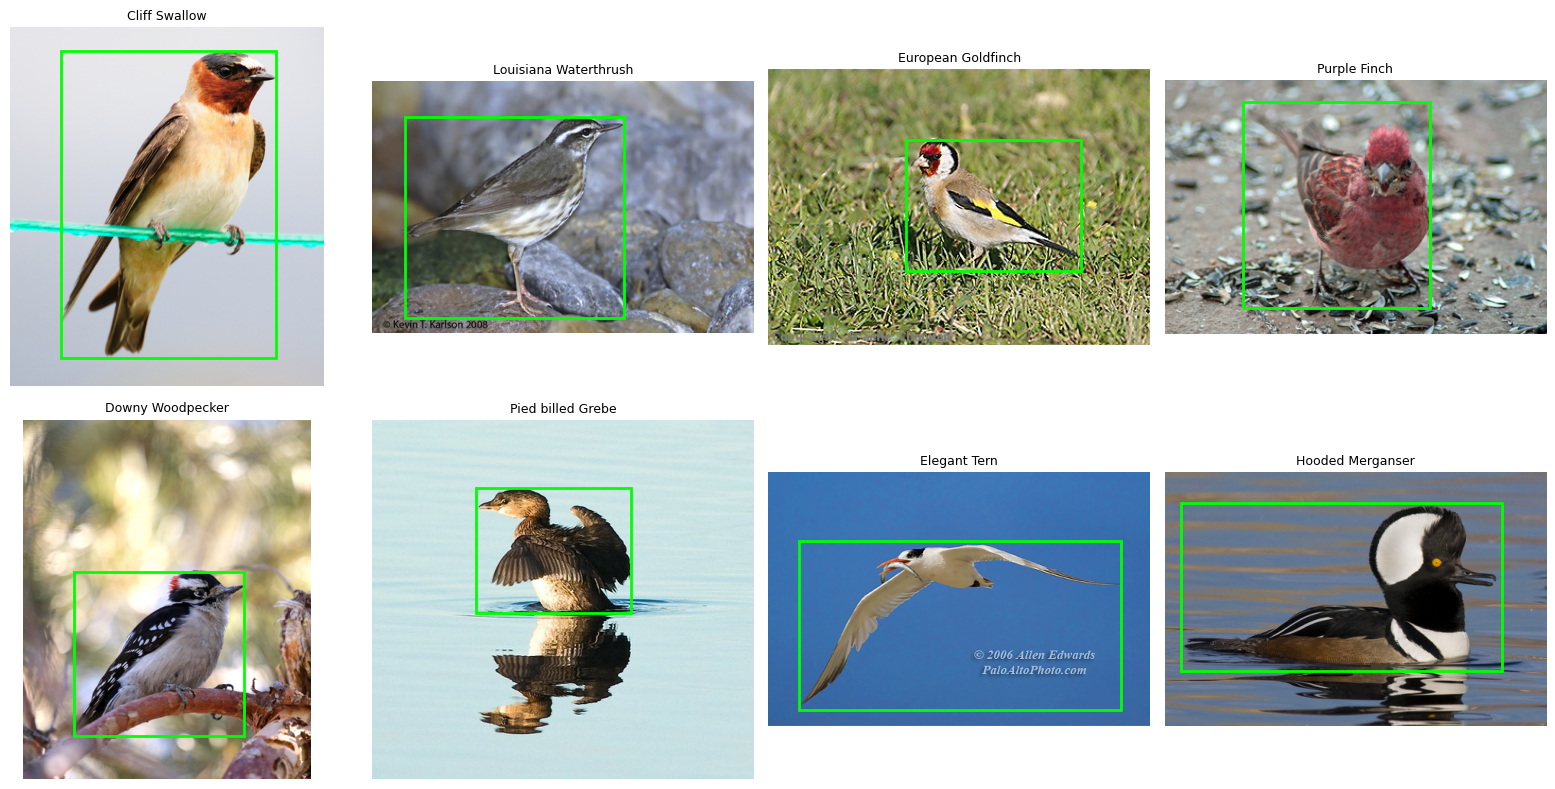

In [24]:
# Look at a few examples with the bounding box drawn (analysis only, not a model input)
import matplotlib.patches as patches
sample = df.sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r.filepath).convert("RGB"))
    ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(r.class_name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Sample Images with Bounding Boxes

Eight randomly sampled training images were displayed with their ground-truth bounding boxes (green) to inspect image quality and variability. The boxes are used for analysis only and are not given to the model.

**Species shown**
- Cliff Swallow, Louisiana Waterthrush, European Goldfinch, Purple Finch, Downy Woodpecker, Pied-billed Grebe, Elegant Tern, Hooded Merganser.

**Observations**
- **Orientation and shape vary.** Some images are portrait (Cliff Swallow, Downy Woodpecker) and others are landscape, which is consistent with the aspect-ratio spread found earlier.
- **Bird size in the frame varies.** The Cliff Swallow fills most of the image, while the European Goldfinch and Pied-billed Grebe occupy a much smaller region.
- **Backgrounds are cluttered and diverse.** Examples include rocks, grass, seeds on the ground, water and sky. The model must learn the bird, not the scene.
- **Poses vary.** Birds are perched, standing, swimming, flying and wings-spread.
- **Reflections and overlays appear.** The grebe's reflection in the water could be mistaken for a second bird, and some images contain copyright watermarks (Louisiana Waterthrush, Elegant Tern).
- **Bounding boxes closely enclose the bird** in most samples, which makes them reliable for the planned qualitative analysis.
- **Species are visually similar**, and the discriminating cues are subtle (for example, the red tones of the Purple Finch versus the yellow wing patch of the Goldfinch). This confirms the fine-grained nature of the task.

**Implications for preprocessing**
- **Horizontal flips** are safe, since birds look valid facing either direction. **Vertical flips** are not used.
- **Color is a key cue** for many species, so color jitter is kept mild and **hue is not altered**.
- **Crop augmentation uses a mild scale (0.5 to 1.0)**, because many birds occupy a small part of the frame and aggressive crops could remove them.
- Background clutter and small birds make the task harder for a from-scratch ViT, which supports the use of augmentation and regularization.